# Myopia Prediction - Machine Learning Project

**Objective:** Build machine learning classification models to predict four myopia-related targets from clinical, lifestyle, and ophthalmological data collected from medical students at the University of Navarra.

**Targets:**

| Target | Type | Classes | Description |
|--------|------|---------|-------------|
| **M** | Binary | SI / NO | Has myopia? |
| **MM** | Binary | SI / NO | Has myopia magna (>6 diopters)? |
| **Combo** | Multi-class | M / MM / C | Combined myopia classification |
| **DCombo** | Multi-class | C / M1 / M2 / MM | Detailed myopia sub-classification |


(SEE BELOW)
> **Key constraint:** Myopia Magna (MM=SI) implies Myopia (M=SI). Similarly:
> - If MM=YES -> Combo=MM, DCombo=MM
> - If healthy (no myopia) -> M=NO, MM=NO, Combo=C, DCombo=C

In [1]:
# === Library Imports ===
try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    import warnings
    from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
    from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
    from sklearn.svm import SVC
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                                ConfusionMatrixDisplay, classification_report)
    from sklearn.pipeline import Pipeline
except ImportError as e:
    print(f"Error importing libraries: {e}. \nYOU CAN INTALL ALL THE LIBRARIES WITH 'pip intall -r requirements.txt'.")
    raise e
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
sns.set_palette('husl')

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## Phase 1: Data Exploring

We start by loading the data, examining its shape, data types, and missing values. Then we visualize the distributions of targets and features to identify patterns, outliers, and relationships.

In [2]:
# Load training data (features + labels) and test data (features only, no labels)
X_train_raw = pd.read_csv('X_train.csv')
Y_train = pd.read_csv('Y_train.csv')
X_test_raw = pd.read_csv('X_test.csv')

print(f"Training features: {X_train_raw.shape[0]} samples x {X_train_raw.shape[1]} features")
print(f"Training labels:   {Y_train.shape[0]} samples x {Y_train.shape[1]} targets")
print(f"Test features:     {X_test_raw.shape[0]} samples x {X_test_raw.shape[1]} features")
print(f"\nTarget columns: {Y_train.columns.tolist()}")

Training features: 132 samples x 49 features
Training labels:   132 samples x 4 targets
Test features:     24 samples x 49 features

Target columns: ['M', 'MM', 'Combo', 'DCombo']


In [3]:
# First 5 rows of the training features
X_train_raw.head()

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


In [4]:
# Data types overview
print("=== Data Types ===\n")
for i, (col, dtype) in enumerate(X_train_raw.dtypes.items()):
    print(f"  {i:2d}. {col:45s} -> {dtype}")

n_num = len(X_train_raw.select_dtypes(include=[np.number]).columns)
n_cat = X_train_raw.shape[1] - n_num
print(f"\nNumerical: {n_num} | Categorical/String: {n_cat}")

=== Data Types ===

   0. fecha                                         -> str
   1. edad                                          -> int64
   2. sexo                                          -> str
   3. origen antepasados (españa)                   -> str
   4. origen antepasados (extranjeros)              -> str
   5. hº deporte sem                                -> float64
   6. hº naturaleza sem                             -> float64
   7. hº ocio exteriores sem                        -> float64
   8. horas exterior sem                            -> float64
   9. hº estudiar sem                               -> int64
  10. hº ocio inter sem                             -> int64
  11. hº act.cerca sem                              -> float64
  12. horas interior sem                            -> float64
  13. Ratio Cerca/Lejos                             -> float64
  14. Exterior Mucho                                -> str
  15. Interior Mcho                                 -> str
  

=== Columns with Missing Values ===

                                  Count  Percent (%)
hº act.cerca sem                    132        100.0
origen antepasados (extranjeros)     98         74.2
Grupo fot                            24         18.2
fototipo                             21         15.9
Familiar miope num.                   4          3.0
origen antepasados (españa)           2          1.5
pat. Ret. Miop magna                  2          1.5
hº ocio exteriores sem                2          1.5
horas interior sem                    1          0.8
familiar miope                        1          0.8


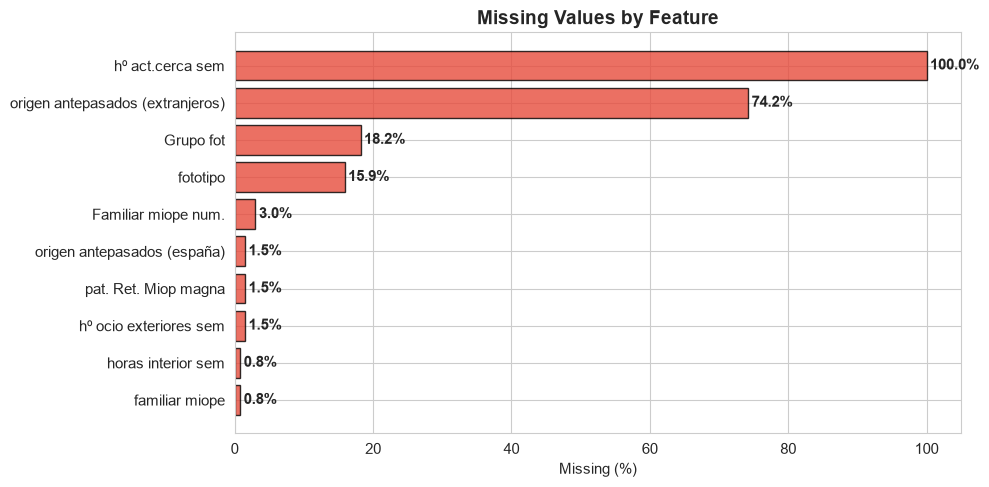

In [5]:
# Missing values analysis
missing = X_train_raw.isnull().sum()
missing_pct = (missing / len(X_train_raw) * 100).round(1)
missing_df = pd.DataFrame({'Count': missing, 'Percent (%)': missing_pct})
missing_df = missing_df[missing_df['Count'] > 0].sort_values('Percent (%)', ascending=False)

print("=== Columns with Missing Values ===\n")
print(missing_df.to_string())

# Visualize
if len(missing_df) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(missing_df.index, missing_df['Percent (%)'], color='#e74c3c', edgecolor='black', alpha=0.8)
    ax.set_xlabel('Missing (%)')
    ax.set_title('Missing Values by Feature', fontsize=14, fontweight='bold')
    ax.invert_yaxis()
    for bar, pct in zip(bars, missing_df['Percent (%)']):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f'{pct}%', va='center', fontweight='bold')
    plt.tight_layout()
    plt.show()

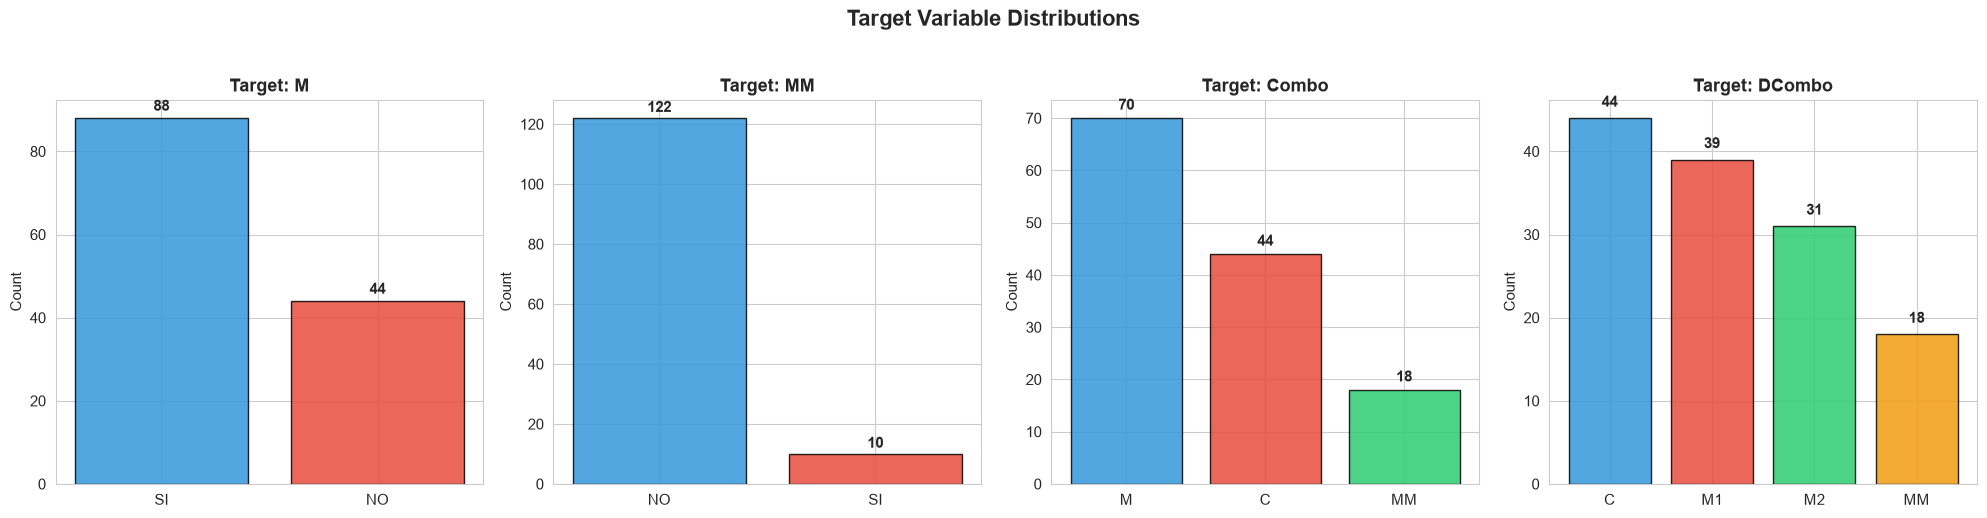


=== Class Distribution Summary ===

  M       : {'SI': np.int64(88), 'NO': np.int64(44)}  (total=132)
  MM      : {'NO': np.int64(122), 'SI': np.int64(10)}  (total=132)
  Combo   : {'M': np.int64(70), 'C': np.int64(44), 'MM': np.int64(18)}  (total=132)
  DCombo  : {'C': np.int64(44), 'M1': np.int64(39), 'M2': np.int64(31), 'MM': np.int64(18)}  (total=132)


In [6]:
# Target distribution analysis
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
palette = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']

for i, col in enumerate(Y_train.columns):
    vc = Y_train[col].value_counts()
    bars = axes[i].bar(vc.index, vc.values, color=palette[:len(vc)], edgecolor='black', alpha=0.85)
    axes[i].set_title(f'Target: {col}', fontsize=13, fontweight='bold')
    axes[i].set_ylabel('Count')
    for bar in bars:
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                    f'{int(bar.get_height())}', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.suptitle('Target Variable Distributions', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Print summary
print("\n=== Class Distribution Summary ===\n")
for col in Y_train.columns:
    counts = dict(Y_train[col].value_counts())
    total = sum(counts.values())
    print(f"  {col:8s}: {counts}  (total={total})")

In [7]:
# Check consistency between the 4 target columns
print("=== Cross-Target Consistency Check ===\n")

# MM=SI should imply M=SI
mm_yes = Y_train[Y_train['MM'] == 'SI']
print(f"Students with MM=SI: {len(mm_yes)}")
print(f"  -> Also have M=SI:     {(mm_yes['M'] == 'SI').sum()} / {len(mm_yes)}")
print(f"  -> Combo=MM:           {(mm_yes['Combo'] == 'MM').sum()} / {len(mm_yes)}")
print(f"  -> DCombo=MM:          {(mm_yes['DCombo'] == 'MM').sum()} / {len(mm_yes)}")

# M=NO should imply Combo=C and DCombo=C
m_no = Y_train[Y_train['M'] == 'NO']
print(f"\nStudents with M=NO: {len(m_no)}")
print(f"  -> Combo=C:            {(m_no['Combo'] == 'C').sum()} / {len(m_no)}")
print(f"  -> DCombo=C:           {(m_no['DCombo'] == 'C').sum()} / {len(m_no)}")

# Combo=MM vs MM=SI
print(f"\nCombo=MM count:  {(Y_train['Combo'] == 'MM').sum()}")
print(f"DCombo=MM count: {(Y_train['DCombo'] == 'MM').sum()}")
print(f"MM=SI count:     {(Y_train['MM'] == 'SI').sum()}")
print("\nNote: There may be discrepancies between the binary MM column")
print("and the Combo/DCombo columns. Each model is trained on its own labels.")

=== Cross-Target Consistency Check ===

Students with MM=SI: 10
  -> Also have M=SI:     10 / 10
  -> Combo=MM:           10 / 10
  -> DCombo=MM:          10 / 10

Students with M=NO: 44
  -> Combo=C:            44 / 44
  -> DCombo=C:           44 / 44

Combo=MM count:  18
DCombo=MM count: 18
MM=SI count:     10

Note: There may be discrepancies between the binary MM column
and the Combo/DCombo columns. Each model is trained on its own labels.


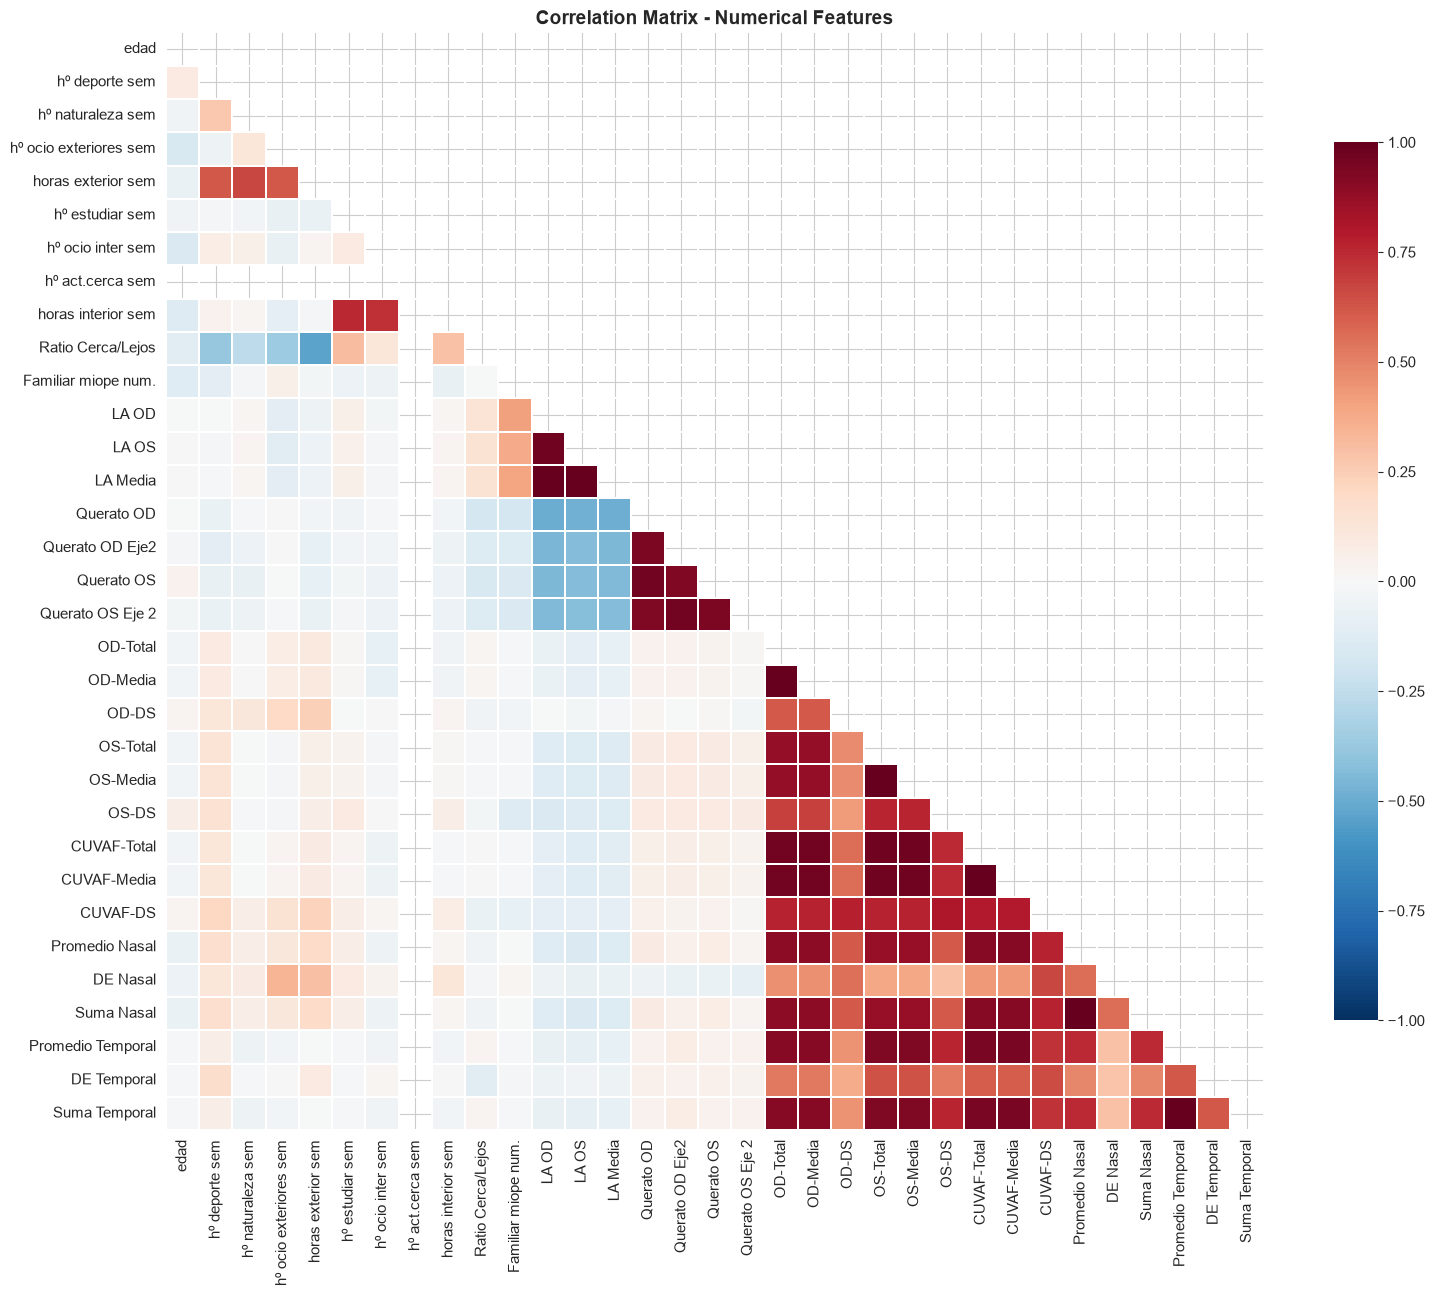


=== Highly Correlated Feature Pairs (|r| > 0.8) ===

  OD-Total                  <-> OD-Media                   r=1.000
  CUVAF-Total               <-> CUVAF-Media                r=1.000
  Promedio Nasal            <-> Suma Nasal                 r=1.000
  Promedio Temporal         <-> Suma Temporal              r=1.000
  OS-Total                  <-> OS-Media                   r=1.000
  LA OS                     <-> LA Media                   r=0.993
  LA OD                     <-> LA Media                   r=0.993
  LA OD                     <-> LA OS                      r=0.973
  OS-Media                  <-> CUVAF-Media                r=0.971
  OS-Media                  <-> CUVAF-Total                r=0.971
  OS-Total                  <-> CUVAF-Media                r=0.971
  OS-Total                  <-> CUVAF-Total                r=0.971
  Querato OD Eje2           <-> Querato OS Eje 2           r=0.968
  OD-Media                  <-> CUVAF-Total                r=0.966
  OD-Med

In [8]:
# Correlation heatmap for numerical features
num_cols = X_train_raw.select_dtypes(include=[np.number]).columns
corr = X_train_raw[num_cols].corr()

plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, annot=False,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title('Correlation Matrix - Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Highly correlated pairs (|r| > 0.8)
print("\n=== Highly Correlated Feature Pairs (|r| > 0.8) ===\n")
high_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.8:
            high_corr.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))
high_corr.sort(key=lambda x: abs(x[2]), reverse=True)
for c1, c2, r in high_corr:
    print(f"  {c1:25s} <-> {c2:25s}  r={r:.3f}")

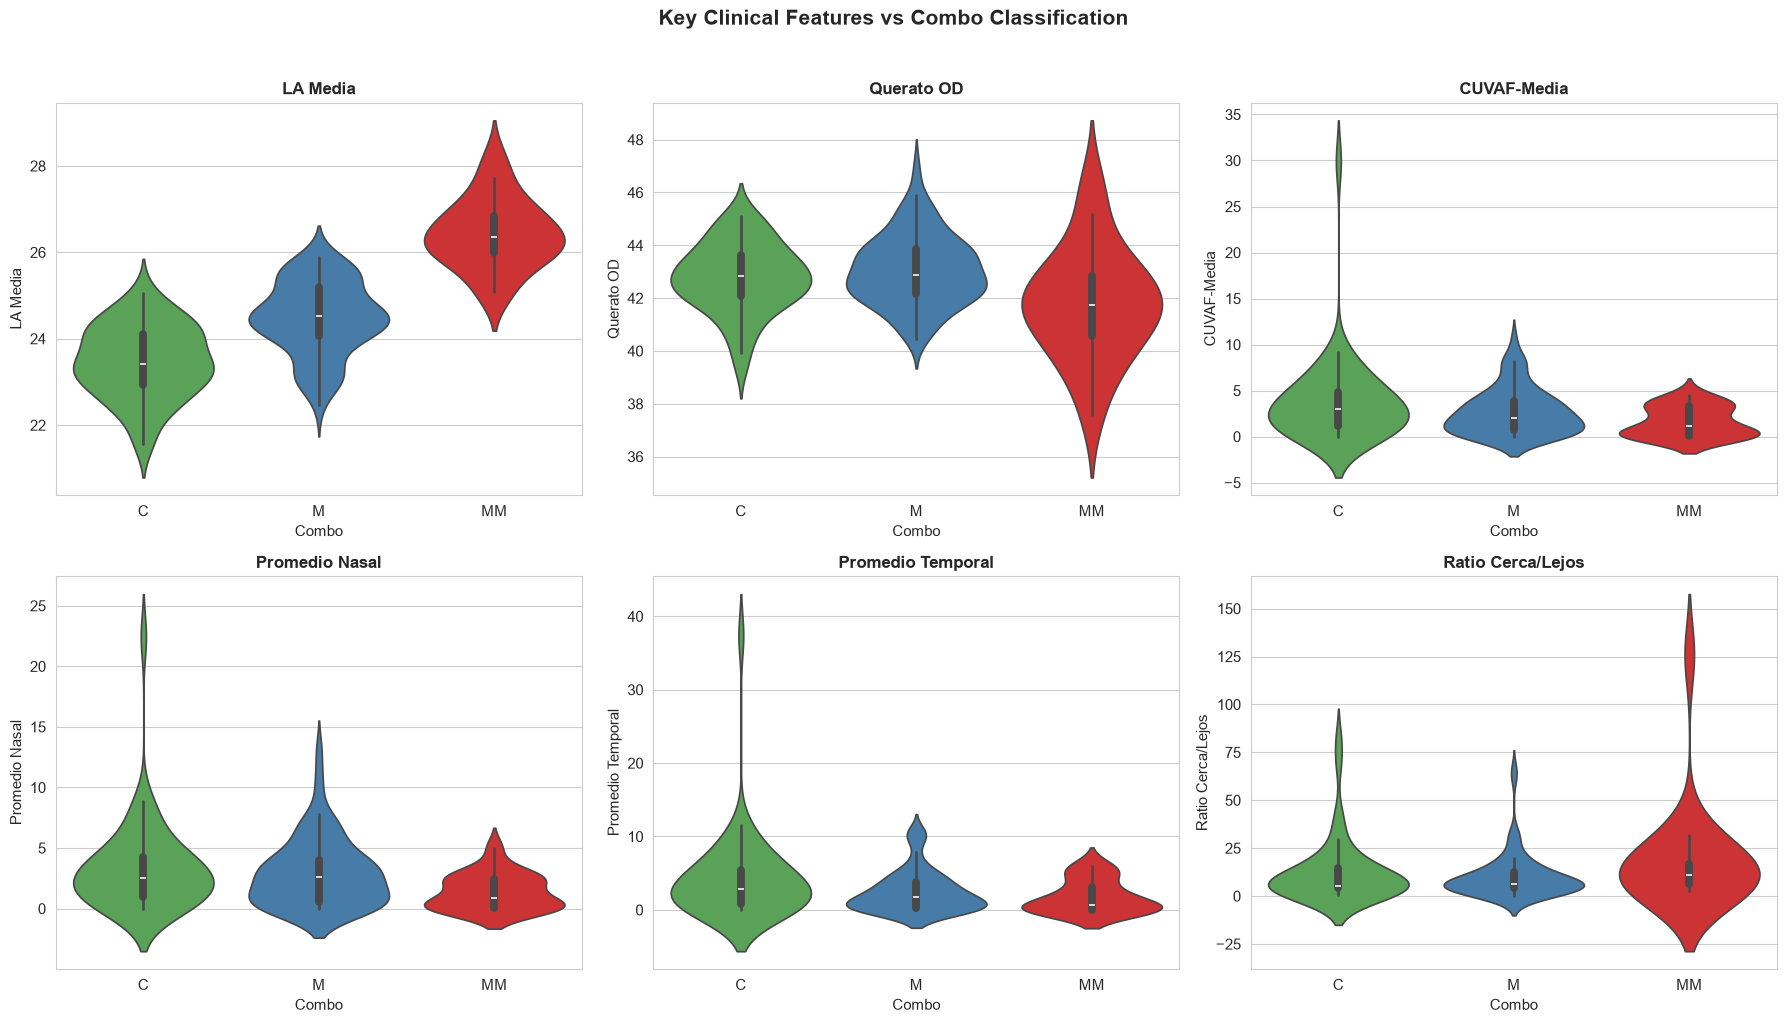

In [9]:
# Key features vs Combo (3-class: C, M, MM)

data_viz = X_train_raw.copy()
data_viz['M'] = Y_train['M'].values
data_viz['MM'] = Y_train['MM'].values
data_viz['Combo'] = Y_train['Combo'].values

# Key clinical features 
key_features = ['LA Media', 'Querato OD', 'CUVAF-Media',
                'Promedio Nasal', 'Promedio Temporal', 'Ratio Cerca/Lejos']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, feat in enumerate(key_features):
    ax = axes[idx // 3][idx % 3]
    sns.violinplot(data=data_viz, x='Combo', y=feat, ax=ax, palette='Set1',
                   hue='Combo', legend=False, inner='box', order=['C', 'M', 'MM'])
    ax.set_title(f'{feat}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Combo')
plt.suptitle('Key Clinical Features vs Combo Classification', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

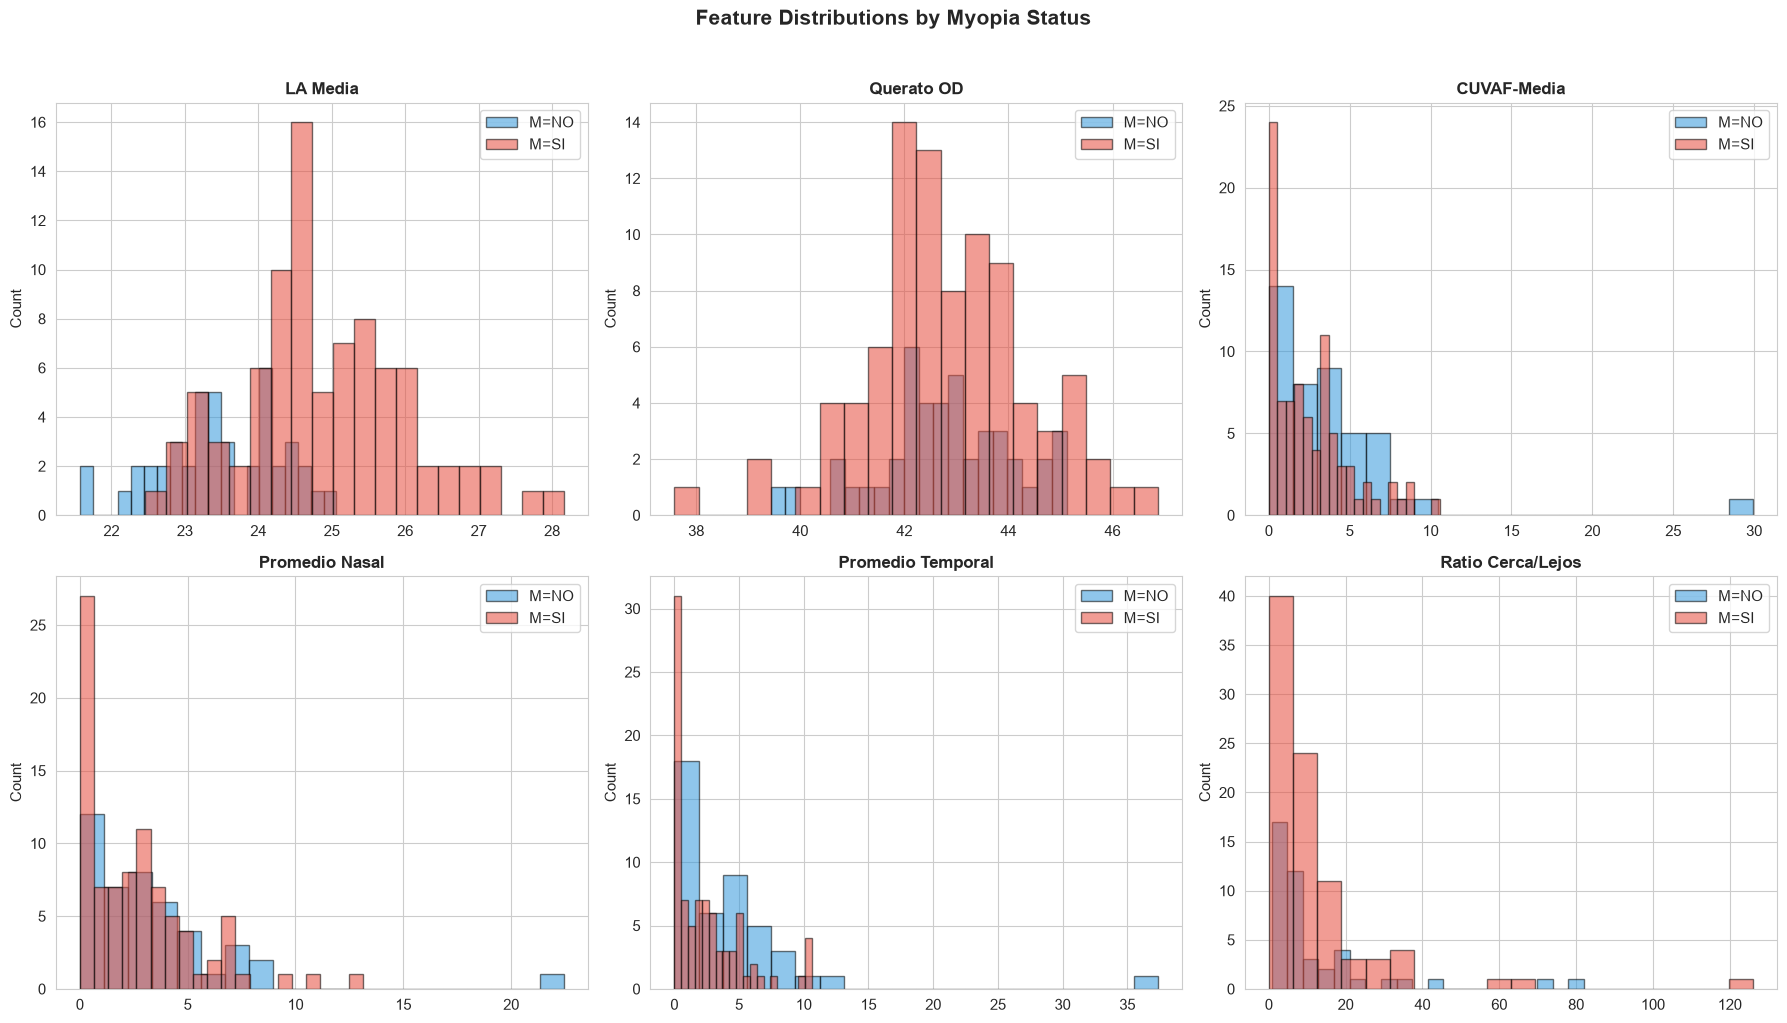

In [10]:
# Feature distributions overlaid by myopia status
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, feat in enumerate(key_features):
    ax = axes[idx // 3][idx % 3]
    for label, color in zip(['NO', 'SI'], ['#3498db', '#e74c3c']):
        subset = data_viz[data_viz['M'] == label][feat].dropna()
        ax.hist(subset, bins=20, alpha=0.55, label=f'M={label}', color=color, edgecolor='black')
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.legend()
    ax.set_ylabel('Count')
plt.suptitle('Feature Distributions by Myopia Status', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Phase 1 - Key Findings

1. **Class imbalance**: MM has only 10 positive samples (7.6%) - we will use `class_weight='balanced'` in all models.
2. **Missing values**: One column (hours near activity) is 100% missing; ancestry columns have many NaN values.
3. **Axial Length (LA Media)** is clearly higher in myopic patients - strong predictor.
4. **High correlations** exist between related measurement pairs (OD/OS, Total/Mean/Std) - some redundancy but tree models handle this well.
5. **Target consistency**: There are discrepancies between the binary MM column (10 SI) and Combo/DCombo MM class (18) - each model will be trained independently on its own target.

---
## Phase 2: Data Cleaning 

### Columns Dropped:
| Column | Reason |
|--------|--------|
| `fecha` | Measurement date - not a clinical predictor |
| `origen antepasados (espana)` | Too many unique regions (~80+), minimal predictive value |
| `origen antepasados (extranjeros)` | 74% missing, too sparse |
| Hours near activity column | 100% missing - completely unusable |
| `familiar miope` (text) | Free-text column; we keep the numeric count `Familiar miope num.` instead |

### Encoding Strategy:
- **Binary SI/NO columns** -> 0/1 mapping
- **`sexo`** -> Mujer=0, Hombre=1
- **`fototipo`** -> Extract numeric value (1-5); non-numeric entries treated as NaN and imputed
- **`Grupo fot`** -> E=0, L=1
- **`Familiar MM SI/NO`** -> No=0, No lo se=1, Si=2 (ordinal)
- **`disp.elec.antes dormir`** -> Nunca=0, A veces=1, Siempre=2 (ordinal)
- **`pat. Ret. Miop magna`** -> No=0, No lo se=1, Si=2 (ordinal)
- **`familiar miope magno`** -> Converted to binary: 1 if a family member has MM, 0 otherwise

### Imputation:
- **Numerical features** -> Median imputation
- **Categorical features** -> Mode (most frequent value) imputation

In [11]:
def preprocess_features(df, is_train=True, fitted_params=None):
    """
    Clean, encode, and impute features.

    Args:
        df: Raw feature DataFrame
        is_train: If True, compute imputation parameters from data
        fitted_params: Dict of imputation values from training set (used when is_train=False)

    Returns:
        Processed DataFrame, fitted imputation parameters
    """
    data = df.copy()
    params = fitted_params.copy() if fitted_params else {}

    # ---- 1. Drop useless columns ----
    # fecha, ancestry columns, 100% missing column
    drop_keywords = ['fecha', 'origen']
    cols_to_drop = [c for c in data.columns if any(kw in c.lower() for kw in drop_keywords)]
    cols_to_drop += [c for c in data.columns if 'act.cerca' in c.lower()]
    data = data.drop(columns=[c for c in cols_to_drop if c in data.columns])

    # ---- 2. Drop text 'familiar miope' (keep numeric 'Familiar miope num.') ----
    if 'familiar miope' in data.columns:
        data = data.drop(columns=['familiar miope'])

    # ---- 3. Convert 'familiar miope magno' to binary, then drop ----
    fam_mm_col = [c for c in data.columns if c.lower() == 'familiar miope magno']
    if fam_mm_col:
        col_name = fam_mm_col[0]
        data['has_family_mm_relative'] = data[col_name].apply(
            lambda x: 0 if pd.isna(x) or str(x).strip().lower() in ['no', 'no lo se'] else 1
        )
        data = data.drop(columns=[col_name])

    # ---- 4. Encode 'sexo' ----
    if 'sexo' in data.columns:
        data['sexo'] = data['sexo'].map({'Mujer': 0, 'Hombre': 1}).fillna(0).astype(int)

    # ---- 5. Encode binary SI/NO columns ----
    binary_si_no = ['Exterior Mucho', 'Interior Mcho', 'fumador', 'toma sol', 'protege sol']
    for col in binary_si_no:
        if col in data.columns:
            data[col] = data[col].map({'NO': 0, 'SI': 1}).fillna(0).astype(int)

    # ---- 6. Encode 'Familiar MM SI/NO' (ordinal) ----
    if 'Familiar MM SI/NO' in data.columns:
        data['Familiar MM SI/NO'] = data['Familiar MM SI/NO'].map(
            {'No': 0, 'No lo se': 1, 'Si': 2}
        )

    # ---- 7. Encode 'disp.elec.antes dormir' (ordinal) ----
    if 'disp.elec.antes dormir' in data.columns:
        data['disp.elec.antes dormir'] = data['disp.elec.antes dormir'].map(
            {'Nunca': 0, 'A veces': 1, 'Siempre': 2}
        )

    # ---- 8. Encode 'fototipo' - extract number ----
    foto_col = [c for c in data.columns if c.lower() == 'fototipo']
    if foto_col:
        col_name = foto_col[0]
        def extract_phototype(x):
            if pd.isna(x):
                return np.nan
            s = str(x)
            for digit in range(1, 7):
                if str(digit) in s:
                    return float(digit)
            return np.nan  # 'E', 'L' -> NaN (will be imputed)
        data[col_name] = data[col_name].apply(extract_phototype)

    # ---- 9. Encode 'Grupo fot' ----
    if 'Grupo fot' in data.columns:
        data['Grupo fot'] = data['Grupo fot'].map({'E': 0, 'L': 1})

    # ---- 10. Encode 'pat. Ret. Miop magna' (ordinal) ----
    pat_cols = [c for c in data.columns if 'pat.' in c.lower() and 'miop' in c.lower()]
    if pat_cols:
        col_name = pat_cols[0]
        def encode_retinal_pathology(x):
            if pd.isna(x):
                return np.nan
            s = str(x).strip().lower()
            if s == 'no':
                return 0
            elif 'no lo' in s:
                return 1
            else:
                return 2
        data[col_name] = data[col_name].apply(encode_retinal_pathology)

    # ---- 11. Impute missing values ----
    if is_train:
        params['impute_values'] = {}
        for col in data.columns:
            if data[col].isnull().any():
                if pd.api.types.is_numeric_dtype(data[col]):
                    fill_val = data[col].median()
                else:
                    mode = data[col].mode()
                    fill_val = mode.iloc[0] if len(mode) > 0 else 0
                params['impute_values'][col] = fill_val
                data[col] = data[col].fillna(fill_val)
    else:
        for col, val in params.get('impute_values', {}).items():
            if col in data.columns:
                data[col] = data[col].fillna(val)
        # Fill any new NaNs not seen in training
        for col in data.columns:
            if data[col].isnull().any():
                if pd.api.types.is_numeric_dtype(data[col]):
                    data[col] = data[col].fillna(data[col].median() if not data[col].dropna().empty else 0)
                else:
                    data[col] = data[col].fillna(0)

    # ---- 12. Ensure all columns are numeric ----
    for col in data.columns:
        if not pd.api.types.is_numeric_dtype(data[col]):
            data[col] = pd.to_numeric(data[col], errors='coerce').fillna(0)

    return data, params

print("Preprocessing function defined.")

Preprocessing function defined.


In [12]:
# Apply preprocessing to training and test sets
X_train, preprocess_params = preprocess_features(X_train_raw, is_train=True)
X_test, _ = preprocess_features(X_test_raw, is_train=False, fitted_params=preprocess_params)

print(f"Processed training set: {X_train.shape[0]} samples x {X_train.shape[1]} features")
print(f"Processed test set:     {X_test.shape[0]} samples x {X_test.shape[1]} features")
print(f"\nRemaining NaN (train): {X_train.isnull().sum().sum()}")
print(f"Remaining NaN (test):  {X_test.isnull().sum().sum()}")
print(f"\n=== Final Feature List ({X_train.shape[1]} features) ===\n")
for i, col in enumerate(X_train.columns):
    print(f"  {i+1:2d}. {col}")

Processed training set: 132 samples x 44 features
Processed test set:     24 samples x 44 features

Remaining NaN (train): 0
Remaining NaN (test):  0

=== Final Feature List (44 features) ===

   1. edad
   2. sexo
   3. hº deporte sem
   4. hº naturaleza sem
   5. hº ocio exteriores sem
   6. horas exterior sem
   7. hº estudiar sem
   8. hº ocio inter sem
   9. horas interior sem
  10. Ratio Cerca/Lejos
  11. Exterior Mucho
  12. Interior Mcho
  13. fototipo
  14. Grupo fot
  15. Familiar miope num.
  16. Familiar MM SI/NO
  17. pat. Ret. Miop magna
  18. fumador
  19. toma sol
  20. protege sol
  21. disp.elec.antes dormir
  22. LA OD
  23. LA OS
  24. LA Media
  25. Querato OD
  26. Querato OD Eje2
  27. Querato OS
  28. Querato OS Eje 2
  29. OD-Total
  30. OD-Media
  31. OD-DS
  32. OS-Total
  33. OS-Media
  34. OS-DS
  35. CUVAF-Total
  36. CUVAF-Media
  37. CUVAF-DS
  38. Promedio Nasal
  39. DE Nasal
  40. Suma Nasal
  41. Promedio Temporal
  42. DE Temporal
  43. Suma Tempora

In [13]:
# Quick sanity check on processed data
X_train.describe().round(2)

,edad,sexo,hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,hº ocio inter sem,horas interior sem,Ratio Cerca/Lejos,...,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal,has_family_mm_relative
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,...,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,22.37,0.27,3.95,1.77,3.56,9.25,38.74,19.80,58.58,12.41,...,11.75,2.94,1.56,2.88,1.08,5.75,3.00,1.05,6.00,0.11
std,0.86,0.44,3.54,2.96,3.95,6.67,15.09,14.47,21.85,16.64,...,13.57,3.39,1.44,3.07,1.35,6.14,4.19,1.26,8.37,0.32
min,20.00,0.00,0.00,0.00,0.00,0.00,5.00,0.00,8.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,22.00,0.00,1.00,0.00,0.00,4.88,30.00,10.00,45.00,4.26,...,3.10,0.78,0.68,0.53,0.20,1.06,0.28,0.11,0.55,0.00
50%,22.00,0.00,3.00,1.00,2.00,8.00,40.00,15.00,57.00,6.62,...,8.59,2.15,1.30,2.36,0.68,4.72,1.84,0.61,3.68,0.00
75%,23.00,1.00,6.00,3.00,5.00,12.25,50.00,28.00,65.25,14.03,...,15.43,3.86,2.02,3.97,1.48,7.94,4.39,1.60,8.78,0.00
max,25.00,1.00,18.00,22.00,21.00,42.00,80.00,80.00,140.00,126.00,...,119.67,29.92,9.41,22.44,10.03,44.88,37.39,7.50,74.79,1.00


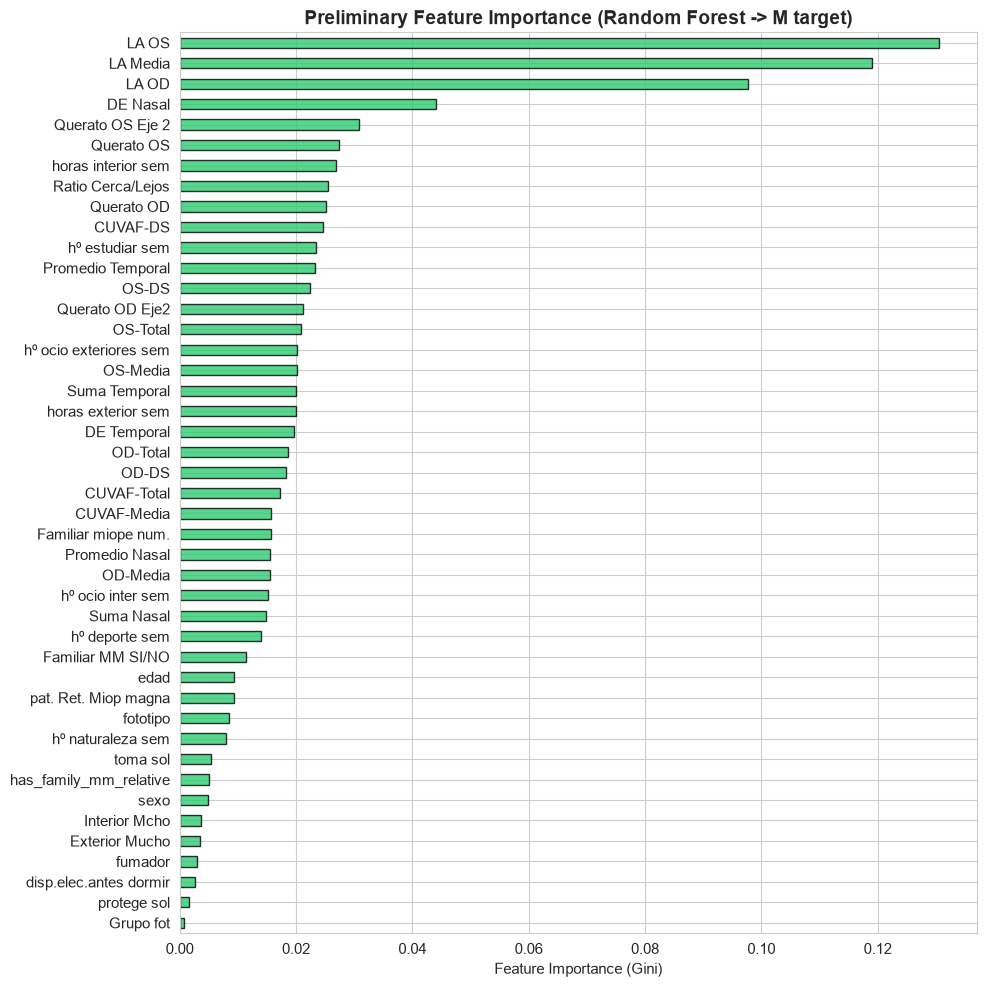


=== Top 15 Most Important Features (for M prediction) ===

  OS-Total                             importance = 0.0209
  Querato OD Eje2                      importance = 0.0213
  OS-DS                                importance = 0.0224
  Promedio Temporal                    importance = 0.0232
  hº estudiar sem                      importance = 0.0234
  CUVAF-DS                             importance = 0.0246
  Querato OD                           importance = 0.0251
  Ratio Cerca/Lejos                    importance = 0.0254
  horas interior sem                   importance = 0.0269
  Querato OS                           importance = 0.0274
  Querato OS Eje 2                     importance = 0.0308
  DE Nasal                             importance = 0.0440
  LA OD                                importance = 0.0977
  LA Media                             importance = 0.1190
  LA OS                                importance = 0.1305


In [14]:
# Preliminary feature importance using Random Forest (target: M)
rf_prelim = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
y_M_encoded = (Y_train['M'] == 'SI').astype(int)
rf_prelim.fit(X_train, y_M_encoded)

importances = pd.Series(rf_prelim.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 10))
importances.plot(kind='barh', color='#2ecc71', edgecolor='black', alpha=0.8)
plt.xlabel('Feature Importance (Gini)')
plt.title('Preliminary Feature Importance (Random Forest -> M target)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top 15 features
print("\n=== Top 15 Most Important Features (for M prediction) ===\n")
for feat, imp in importances.tail(15).items():
    print(f"  {feat:35s}  importance = {imp:.4f}")

### Phase 2 - Summary

After preprocessing, we reduced the feature set from 49 to 40 clean, numeric features:
- Dropped 5+ columns that were uninformative (date, ancestry, 100% missing).
- Encoded all categorical variables into numeric form.
- Imputed missing values using median (numerical) and mode (categorical).
- The preliminary Random Forest analysis shows that **Axial Length (LA)**, **Keratometry**, and **CUVAF** measurements are the most important features for predicting myopia.

> We keep **all remaining features** for tree-based models (Random Forest and Gradient Boosting), which can handle high dimensionality via internal feature selection. For SVM, we apply StandardScaler within a pipeline.

---
## Phase 3: Model Training & Evaluation

### Models used

We train **three different models** for each of the 4 targets:

| Model | Why we chose it | Key hyperparameters |
|-------|----------------|--------------------|
| **Random Forest** | Robust ensemble of decision trees; naturally handles mixed feature types and high dimensionality; resistant to overfitting with enough trees | 300 trees, balanced class weights |
| **Histogram-based Gradient Boosting** | builds trees sequentially to correct errors; often achieves best accuracy | 300 iterations, max depth 6, lr=0.1, balanced weights |
| **SVM (RBF kernel)** | Effective for small datasets; finds optimal decision boundary; with  | C=1.0, auto gamma, StandardScaler pipeline, balanced weights |

### How we select the best model (selection logic)

**For each target independently**, we use **Stratified 5-Fold Cross-Validation**:
1. The dataset is split into 5 folds, preserving class proportions in each fold.
2. Each model is trained on 4 folds and validated on the remaining fold, repeated 5 times.
3. We compute two metrics per model:
   - **Accuracy**: Percentage of correct predictions.
   - **Macro F1-Score**: The harmonic mean of precision and recall, averaged equally across all classes.

**Why Macro F1 instead of Accuracy?** Because accuracy can be misleading with imbalanced classes. For example, a model that always predicts MM=NO would get 92.4% accuracy (122/132) but completely fail on the 10 positive cases. **Macro F1 penalizes models that ignore minority classes**, making it the right metric for our imbalanced targets.

**The best model for each target** is simply the one with the **highest mean Macro F1-Score** across the 5 validation folds. Since each target may have different characteristics (binary vs multi-class, different imbalance levels), **a different model can be selected for each target**.

All models use `class_weight='balanced'` to automatically upweight minority class samples during training.

In [15]:
# Cross-validation setup
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def get_models():
    """Return a dictionary of model name -> model instance."""
    return {
        'Random Forest': RandomForestClassifier(
            n_estimators=300, max_depth=None, min_samples_split=5,
            class_weight='balanced', random_state=42, n_jobs=-1
        ),
        'Hist Gradient Boosting': HistGradientBoostingClassifier(
            max_iter=300, max_depth=6, learning_rate=0.1,
            class_weight='balanced', random_state=42
        ),
        'SVM (RBF)': Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='rbf', C=1.0, gamma='scale',
                       class_weight='balanced', random_state=42))
        ]),
    }

def evaluate_target(X, y, target_name):
    """Train and evaluate all models for a given target using Stratified K-Fold CV."""
    models = get_models()
    results = {}

    print(f"{'='*65}")
    print(f"  Target: {target_name}")
    print(f"  Classes: {dict(pd.Series(y).value_counts())}")
    print(f"{'='*65}\n")

    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=CV,
                               scoring=['accuracy', 'f1_macro'],
                               return_train_score=True)
        results[name] = {
            'train_acc': scores['train_accuracy'].mean(),
            'val_acc': scores['test_accuracy'].mean(),
            'val_acc_std': scores['test_accuracy'].std(),
            'val_f1': scores['test_f1_macro'].mean(),
            'val_f1_std': scores['test_f1_macro'].std(),
        }
        print(f"  {name:25s} | Val Acc: {results[name]['val_acc']:.3f} +/- {results[name]['val_acc_std']:.3f}"
              f" | Val F1: {results[name]['val_f1']:.3f} +/- {results[name]['val_f1_std']:.3f}"
              f" | Train Acc: {results[name]['train_acc']:.3f}")

    # Best model by F1
    best_name = max(results, key=lambda k: results[k]['val_f1'])
    print(f"\n  >>> Best model for {target_name}: {best_name} "
          f"(F1 = {results[best_name]['val_f1']:.3f})")

    # Confusion matrices for all models
    labels = sorted(pd.Series(y).unique())
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for idx, (mname, mmodel) in enumerate(get_models().items()):
        y_pred = cross_val_predict(mmodel, X, y, cv=CV)
        cm_i = confusion_matrix(y, y_pred, labels=labels)
        disp = ConfusionMatrixDisplay(cm_i, display_labels=labels)
        disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
        f1_val = f1_score(y, y_pred, average='macro')
        marker = ' *' if mname == best_name else ''
        axes[idx].set_title(f'{mname} (F1={f1_val:.3f}){marker}', fontweight='bold')
    plt.suptitle(f'Confusion Matrices - {target_name}', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

    # Classification report for best model
    best_model = get_models()[best_name]
    y_pred_best = cross_val_predict(best_model, X, y, cv=CV)
    print(f"\n  Classification Report - {best_name} ({target_name}):\n")
    print(classification_report(y, y_pred_best, target_names=labels))

    return results, best_name

# Store all results
all_results = {}
best_models = {}

print("Training functions defined. Ready for model evaluation.")

Training functions defined. Ready for model evaluation.


### Target 1: M (Myopia - Binary: SI / NO)

  Target: M (Myopia)
  Classes: {'SI': np.int64(88), 'NO': np.int64(44)}

  Random Forest             | Val Acc: 0.757 +/- 0.081 | Val F1: 0.733 +/- 0.100 | Train Acc: 0.998
  Hist Gradient Boosting    | Val Acc: 0.749 +/- 0.056 | Val F1: 0.720 +/- 0.054 | Train Acc: 1.000
  SVM (RBF)                 | Val Acc: 0.719 +/- 0.068 | Val F1: 0.692 +/- 0.072 | Train Acc: 0.943

  >>> Best model for M (Myopia): Random Forest (F1 = 0.733)


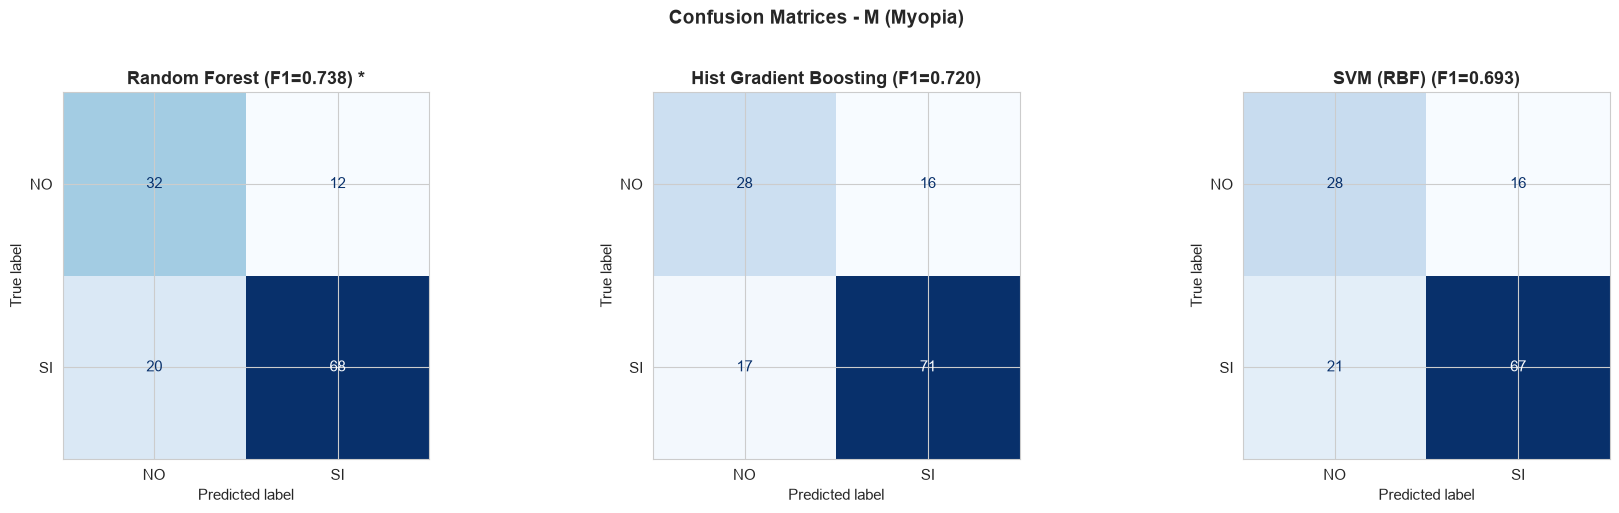


  Classification Report - Random Forest (M (Myopia)):

              precision    recall  f1-score   support

          NO       0.62      0.73      0.67        44
          SI       0.85      0.77      0.81        88

    accuracy                           0.76       132
   macro avg       0.73      0.75      0.74       132
weighted avg       0.77      0.76      0.76       132



In [16]:
results_M, best_M = evaluate_target(X_train, Y_train['M'], 'M (Myopia)')
all_results['M'] = results_M
best_models['M'] = best_M

### Target 2: MM (Myopia Magna - Binary: SI / NO)

> **Warning:** Heavily imbalanced - only 10 positive samples (7.6%). Metrics may have high variance across folds.

  Target: MM (Myopia Magna)
  Classes: {'NO': np.int64(122), 'SI': np.int64(10)}

  Random Forest             | Val Acc: 0.901 +/- 0.019 | Val F1: 0.603 +/- 0.107 | Train Acc: 0.985
  Hist Gradient Boosting    | Val Acc: 0.901 +/- 0.019 | Val F1: 0.574 +/- 0.127 | Train Acc: 1.000
  SVM (RBF)                 | Val Acc: 0.940 +/- 0.030 | Val F1: 0.634 +/- 0.207 | Train Acc: 1.000

  >>> Best model for MM (Myopia Magna): SVM (RBF) (F1 = 0.634)


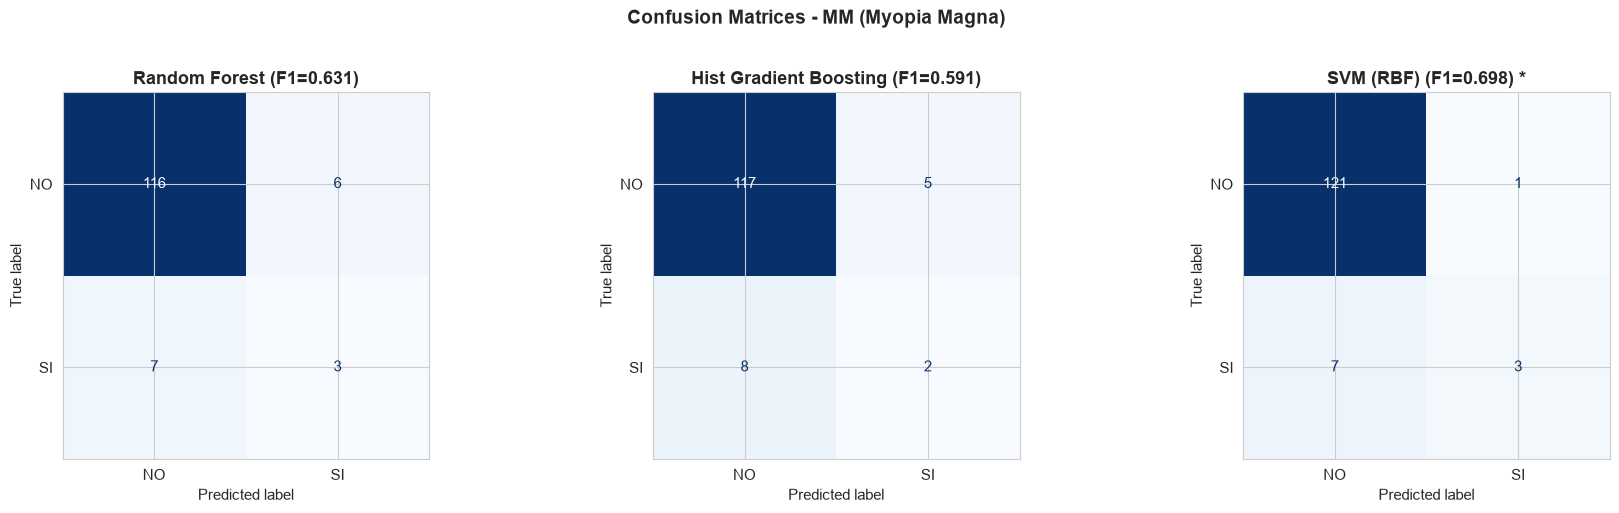


  Classification Report - SVM (RBF) (MM (Myopia Magna)):

              precision    recall  f1-score   support

          NO       0.95      0.99      0.97       122
          SI       0.75      0.30      0.43        10

    accuracy                           0.94       132
   macro avg       0.85      0.65      0.70       132
weighted avg       0.93      0.94      0.93       132



In [17]:
results_MM, best_MM = evaluate_target(X_train, Y_train['MM'], 'MM (Myopia Magna)')
all_results['MM'] = results_MM
best_models['MM'] = best_MM

### Target 3: Combo (Multi-class: C / M / MM)

  Target: Combo
  Classes: {'M': np.int64(70), 'C': np.int64(44), 'MM': np.int64(18)}

  Random Forest             | Val Acc: 0.703 +/- 0.162 | Val F1: 0.719 +/- 0.158 | Train Acc: 0.991
  Hist Gradient Boosting    | Val Acc: 0.642 +/- 0.094 | Val F1: 0.628 +/- 0.087 | Train Acc: 1.000
  SVM (RBF)                 | Val Acc: 0.636 +/- 0.051 | Val F1: 0.645 +/- 0.067 | Train Acc: 0.926

  >>> Best model for Combo: Random Forest (F1 = 0.719)


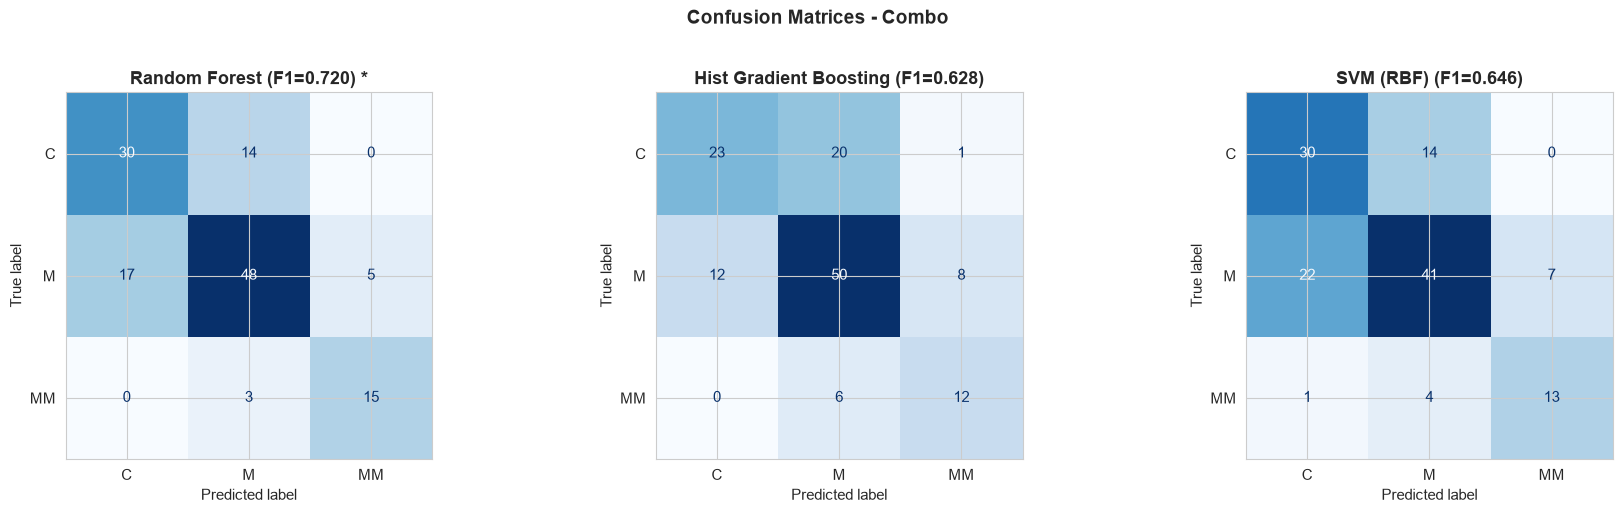


  Classification Report - Random Forest (Combo):

              precision    recall  f1-score   support

           C       0.64      0.68      0.66        44
           M       0.74      0.69      0.71        70
          MM       0.75      0.83      0.79        18

    accuracy                           0.70       132
   macro avg       0.71      0.73      0.72       132
weighted avg       0.71      0.70      0.70       132



In [18]:
results_Combo, best_Combo = evaluate_target(X_train, Y_train['Combo'], 'Combo')
all_results['Combo'] = results_Combo
best_models['Combo'] = best_Combo

### Target 4: DCombo (Multi-class: C / M1 / M2 / MM)

  Target: DCombo
  Classes: {'C': np.int64(44), 'M1': np.int64(39), 'M2': np.int64(31), 'MM': np.int64(18)}

  Random Forest             | Val Acc: 0.605 +/- 0.097 | Val F1: 0.635 +/- 0.076 | Train Acc: 1.000
  Hist Gradient Boosting    | Val Acc: 0.470 +/- 0.055 | Val F1: 0.479 +/- 0.082 | Train Acc: 1.000
  SVM (RBF)                 | Val Acc: 0.546 +/- 0.046 | Val F1: 0.552 +/- 0.055 | Train Acc: 0.926

  >>> Best model for DCombo: Random Forest (F1 = 0.635)


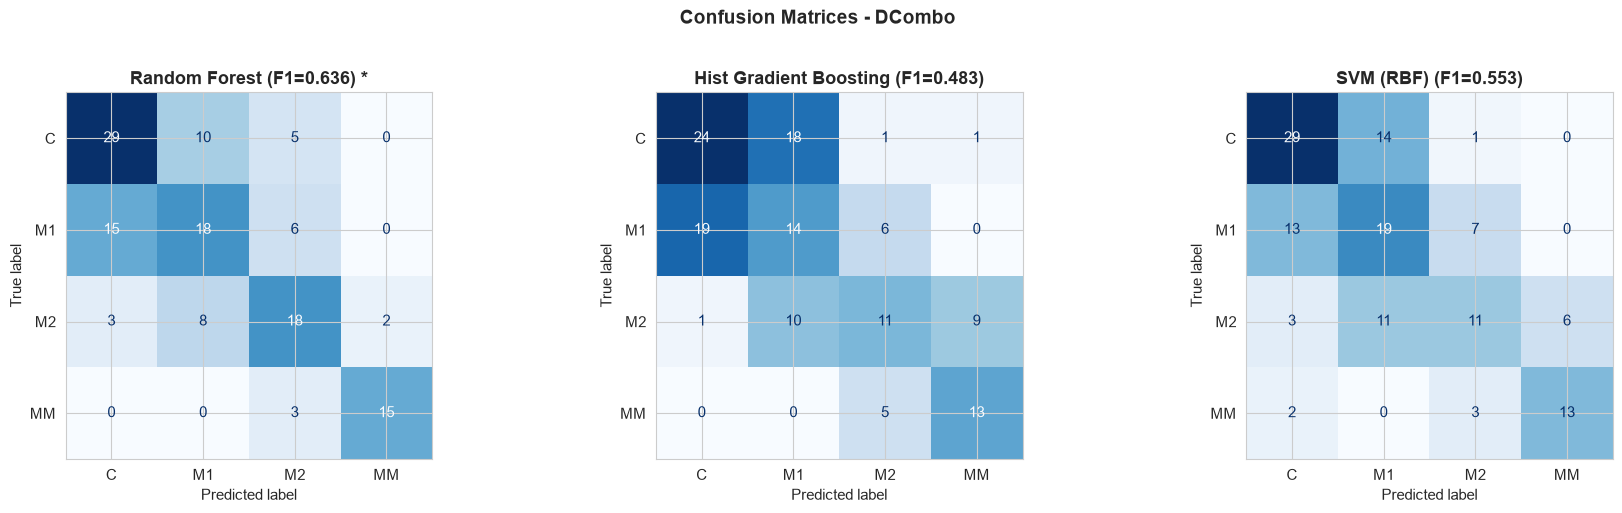


  Classification Report - Random Forest (DCombo):

              precision    recall  f1-score   support

           C       0.62      0.66      0.64        44
          M1       0.50      0.46      0.48        39
          M2       0.56      0.58      0.57        31
          MM       0.88      0.83      0.86        18

    accuracy                           0.61       132
   macro avg       0.64      0.63      0.64       132
weighted avg       0.61      0.61      0.61       132



In [19]:
results_DCombo, best_DCombo = evaluate_target(X_train, Y_train['DCombo'], 'DCombo')
all_results['DCombo'] = results_DCombo
best_models['DCombo'] = best_DCombo


  SUMMARY: Best Model per Target


Target    Best Model    Val Accuracy  Val F1 (macro)
     M Random Forest 0.757 +/- 0.081 0.733 +/- 0.100
    MM     SVM (RBF) 0.940 +/- 0.030 0.634 +/- 0.207
 Combo Random Forest 0.703 +/- 0.162 0.719 +/- 0.158
DCombo Random Forest 0.605 +/- 0.097 0.635 +/- 0.076


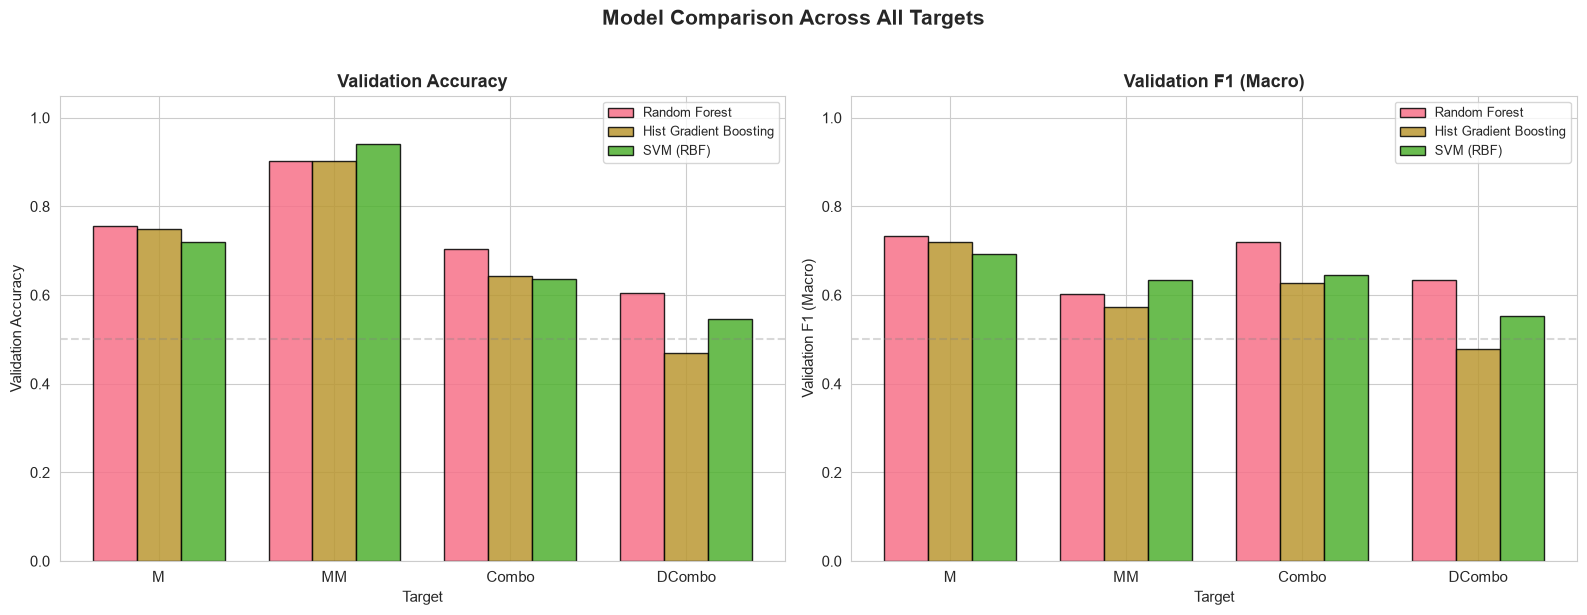

In [20]:
# === Summary of All Results ===
print("\n" + "="*80)
print("  SUMMARY: Best Model per Target")
print("="*80)

summary_rows = []
for target in ['M', 'MM', 'Combo', 'DCombo']:
    best = best_models[target]
    r = all_results[target][best]
    summary_rows.append({
        'Target': target,
        'Best Model': best,
        'Val Accuracy': f"{r['val_acc']:.3f} +/- {r['val_acc_std']:.3f}",
        'Val F1 (macro)': f"{r['val_f1']:.3f} +/- {r['val_f1_std']:.3f}",
    })

summary_df = pd.DataFrame(summary_rows)
print("\n")
print(summary_df.to_string(index=False))

# Detailed comparison chart
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
targets = ['M', 'MM', 'Combo', 'DCombo']
model_names = list(get_models().keys())
x = np.arange(len(targets))
width = 0.25

for metric_idx, (metric, title) in enumerate([('val_acc', 'Validation Accuracy'), ('val_f1', 'Validation F1 (Macro)')]):
    ax = axes[metric_idx]
    for i, mname in enumerate(model_names):
        vals = [all_results[t][mname][metric] for t in targets]
        bars = ax.bar(x + i*width, vals, width, label=mname, alpha=0.85, edgecolor='black')
    ax.set_xlabel('Target')
    ax.set_ylabel(title)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(targets)
    ax.legend(fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.3)

plt.suptitle('Model Comparison Across All Targets', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Phase 3 - Summary & Model Selection Rationale

Each target was evaluated with 3 models using Stratified 5-Fold CV. The best model per target was selected **automatically** based on the **highest mean Macro F1-Score** across folds.

**Why this approach works:**
- We evaluate each target **independently** because they have different class distributions and difficulty levels.
- A model that works best for binary myopia detection (M) may not be best for 4-class sub-typing (DCombo).
- By using Macro F1 (not accuracy), we ensure the selected model genuinely performs well on **all classes, including rare ones**.

Key observations:
- **M (binary)**: Relatively balanced (88 SI vs 44 NO). Tree-based models typically perform well.
- **MM (binary)**: Extreme imbalance (10 SI vs 122 NO). Only ~2 positive samples per CV fold, so metrics have high variance.
- **Combo (3-class)**: MM class (18 samples) is hardest to distinguish.
- **DCombo (4-class)**: Most complex task, 4 classes with varying sizes.

In [21]:
# === Explicit Model Selection Summary ===
print("=" * 70)
print("  BEST MODEL SELECTED FOR EACH TARGET")
print("  (Selected by highest Macro F1-Score on cross-validation)")
print("=" * 70)

for target in ['M', 'MM', 'Combo', 'DCombo']:
    best = best_models[target]
    r = all_results[target][best]
    print(f"\n  Target: {target}")
    print(f"  Winner: {best}")
    print(f"  Macro F1: {r['val_f1']:.3f} +/- {r['val_f1_std']:.3f}")
    print(f"  Accuracy: {r['val_acc']:.3f} +/- {r['val_acc_std']:.3f}")
    # Show all models for comparison
    print(f"  All models compared:")
    for mname, mresult in all_results[target].items():
        flag = ' <-- SELECTED' if mname == best else ''
        print(f"    {mname:25s} F1={mresult['val_f1']:.3f}  Acc={mresult['val_acc']:.3f}{flag}")

print("\n" + "=" * 70)
print("  These models will be used in Phase 4 for final predictions.")
print("=" * 70)

  BEST MODEL SELECTED FOR EACH TARGET
  (Selected by highest Macro F1-Score on cross-validation)

  Target: M
  Winner: Random Forest
  Macro F1: 0.733 +/- 0.100
  Accuracy: 0.757 +/- 0.081
  All models compared:
    Random Forest             F1=0.733  Acc=0.757 <-- SELECTED
    Hist Gradient Boosting    F1=0.720  Acc=0.749
    SVM (RBF)                 F1=0.692  Acc=0.719

  Target: MM
  Winner: SVM (RBF)
  Macro F1: 0.634 +/- 0.207
  Accuracy: 0.940 +/- 0.030
  All models compared:
    Random Forest             F1=0.603  Acc=0.901
    Hist Gradient Boosting    F1=0.574  Acc=0.901
    SVM (RBF)                 F1=0.634  Acc=0.940 <-- SELECTED

  Target: Combo
  Winner: Random Forest
  Macro F1: 0.719 +/- 0.158
  Accuracy: 0.703 +/- 0.162
  All models compared:
    Random Forest             F1=0.719  Acc=0.703 <-- SELECTED
    Hist Gradient Boosting    F1=0.628  Acc=0.642
    SVM (RBF)                 F1=0.645  Acc=0.636

  Target: DCombo
  Winner: Random Forest
  Macro F1: 0.635 +/- 0

---
## Phase 4: Final Predictions on Test Set

### How we generate final predictions

For each of the 4 targets, we:
1. Take the **best model selected in Phase 3** (the one with highest cross-validated Macro F1).
2. **Re-train it on the FULL training set** (all 132 samples) — during CV we only used 80% for training; now we use 100% to maximize the information the model learns from.
3. **Predict** on the 24 unlabeled test samples.

Note: Each target may use a **different model**. For example, Random Forest might be best for M, while Gradient Boosting might be best for DCombo. The `best_models` dictionary (populated in Phase 3) stores which model won for each target.

### Post-processing: Enforcing logical constraints

Since the 4 predictions are made independently, they might be inconsistent. We enforce these medical/logical rules:

| Rule | Condition | Action |
|------|-----------|--------|
| **Rule 1** | MM=SI (has myopia magna) | Force M=SI, Combo=MM, DCombo=MM |
| **Rule 2** | M=NO (no myopia at all) | Force MM=NO, Combo=C, DCombo=C |
| **Rule 3** | M=SI, MM=NO (myopia but not magna) | Force Combo=M, DCombo must be M1 or M2 |

This ensures that a patient classified with myopia magna is always also classified as myopic, and a healthy patient is always classified as control across all targets.

In [22]:
# Train best models on full training set and predict test set
predictions = {}

for target in ['M', 'MM', 'Combo', 'DCombo']:
    best_name = best_models[target]
    model = get_models()[best_name]

    # Train on full training set
    model.fit(X_train, Y_train[target])

    # Predict on test set
    preds = model.predict(X_test)
    predictions[target] = list(preds)

    print(f"Target {target:7s} | Model: {best_name:25s} | Predictions: {dict(pd.Series(preds).value_counts())}")

print("\nAll predictions generated (before constraint enforcement).")

Target M       | Model: Random Forest             | Predictions: {'SI': np.int64(16), 'NO': np.int64(8)}
Target MM      | Model: SVM (RBF)                 | Predictions: {'NO': np.int64(23), 'SI': np.int64(1)}
Target Combo   | Model: Random Forest             | Predictions: {'M': np.int64(11), 'C': np.int64(8), 'MM': np.int64(5)}
Target DCombo  | Model: Random Forest             | Predictions: {'M1': np.int64(8), 'C': np.int64(7), 'MM': np.int64(5), 'M2': np.int64(4)}

All predictions generated (before constraint enforcement).


In [23]:
# Apply logical constraints for consistency
print("=== Applying Logical Constraints ===\n")

changes_made = 0
for i in range(len(predictions['M'])):
    m  = predictions['M'][i]
    mm = predictions['MM'][i]

    # Rule 1: If MM=SI -> M must be SI, Combo must be MM, DCombo must be MM
    if mm == 'SI':
        if predictions['M'][i] != 'SI':
            print(f"  Sample {i}: MM=SI but M={predictions['M'][i]} -> forcing M=SI")
            predictions['M'][i] = 'SI'
            changes_made += 1
        if predictions['Combo'][i] != 'MM':
            print(f"  Sample {i}: MM=SI but Combo={predictions['Combo'][i]} -> forcing Combo=MM")
            predictions['Combo'][i] = 'MM'
            changes_made += 1
        if predictions['DCombo'][i] != 'MM':
            print(f"  Sample {i}: MM=SI but DCombo={predictions['DCombo'][i]} -> forcing DCombo=MM")
            predictions['DCombo'][i] = 'MM'
            changes_made += 1

    # Rule 2: If M=NO -> MM must be NO, Combo must be C, DCombo must be C
    elif predictions['M'][i] == 'NO':
        if predictions['MM'][i] != 'NO':
            print(f"  Sample {i}: M=NO but MM={predictions['MM'][i]} -> forcing MM=NO")
            predictions['MM'][i] = 'NO'
            changes_made += 1
        if predictions['Combo'][i] != 'C':
            print(f"  Sample {i}: M=NO but Combo={predictions['Combo'][i]} -> forcing Combo=C")
            predictions['Combo'][i] = 'C'
            changes_made += 1
        if predictions['DCombo'][i] != 'C':
            print(f"  Sample {i}: M=NO but DCombo={predictions['DCombo'][i]} -> forcing DCombo=C")
            predictions['DCombo'][i] = 'C'
            changes_made += 1

    # Rule 3: If M=SI and MM=NO -> Combo must be M, DCombo must be M1 or M2
    else:
        if predictions['Combo'][i] != 'M':
            print(f"  Sample {i}: M=SI, MM=NO but Combo={predictions['Combo'][i]} -> forcing Combo=M")
            predictions['Combo'][i] = 'M'
            changes_made += 1
        if predictions['DCombo'][i] not in ('M1', 'M2'):
            print(f"  Sample {i}: M=SI, MM=NO but DCombo={predictions['DCombo'][i]} -> forcing DCombo=M1")
            predictions['DCombo'][i] = 'M1'
            changes_made += 1

print(f"\nTotal constraint corrections: {changes_made}")
print("\n=== Final Prediction Distributions (after constraints) ===\n")
for target in ['M', 'MM', 'Combo', 'DCombo']:
    print(f"  {target:7s}: {dict(pd.Series(predictions[target]).value_counts())}")

=== Applying Logical Constraints ===

  Sample 0: M=SI, MM=NO but Combo=MM -> forcing Combo=M
  Sample 0: M=SI, MM=NO but DCombo=MM -> forcing DCombo=M1
  Sample 1: M=NO but Combo=M -> forcing Combo=C
  Sample 1: M=NO but DCombo=M1 -> forcing DCombo=C
  Sample 4: M=NO but Combo=M -> forcing Combo=C
  Sample 5: M=SI, MM=NO but DCombo=C -> forcing DCombo=M1
  Sample 7: M=SI, MM=NO but Combo=MM -> forcing Combo=M
  Sample 7: M=SI, MM=NO but DCombo=MM -> forcing DCombo=M1
  Sample 8: M=NO but DCombo=M1 -> forcing DCombo=C
  Sample 9: M=SI, MM=NO but Combo=MM -> forcing Combo=M
  Sample 9: M=SI, MM=NO but DCombo=MM -> forcing DCombo=M1
  Sample 10: M=SI, MM=NO but Combo=C -> forcing Combo=M
  Sample 15: M=SI, MM=NO but Combo=MM -> forcing Combo=M
  Sample 15: M=SI, MM=NO but DCombo=MM -> forcing DCombo=M1
  Sample 20: M=SI, MM=NO but Combo=C -> forcing Combo=M

Total constraint corrections: 15

=== Final Prediction Distributions (after constraints) ===

  M      : {'SI': np.int64(16), 'NO':

In [24]:
# Save predictions to TXT file
pred_df = pd.DataFrame(predictions)
pred_df.to_csv('test_predictions.txt', sep='\t', index=False)

print("Predictions saved to 'test_predictions.txt'")
print("\nFinal predictions table:")
print(pred_df.to_string(index=True))
print(f"\nTotal test samples: {len(pred_df)}")

Predictions saved to 'test_predictions.txt'

Final predictions table:
     M  MM Combo DCombo
0   SI  NO     M     M1
1   NO  NO     C      C
2   SI  SI    MM     MM
3   SI  NO     M     M1
4   NO  NO     C      C
5   SI  NO     M     M1
6   SI  NO     M     M1
7   SI  NO     M     M1
8   NO  NO     C      C
9   SI  NO     M     M1
10  SI  NO     M     M2
11  NO  NO     C      C
12  SI  NO     M     M1
13  SI  NO     M     M1
14  SI  NO     M     M1
15  SI  NO     M     M1
16  SI  NO     M     M2
17  NO  NO     C      C
18  NO  NO     C      C
19  SI  NO     M     M2
20  SI  NO     M     M1
21  NO  NO     C      C
22  SI  NO     M     M2
23  NO  NO     C      C

Total test samples: 24


---
## Phase 5: Summary & Conclusions

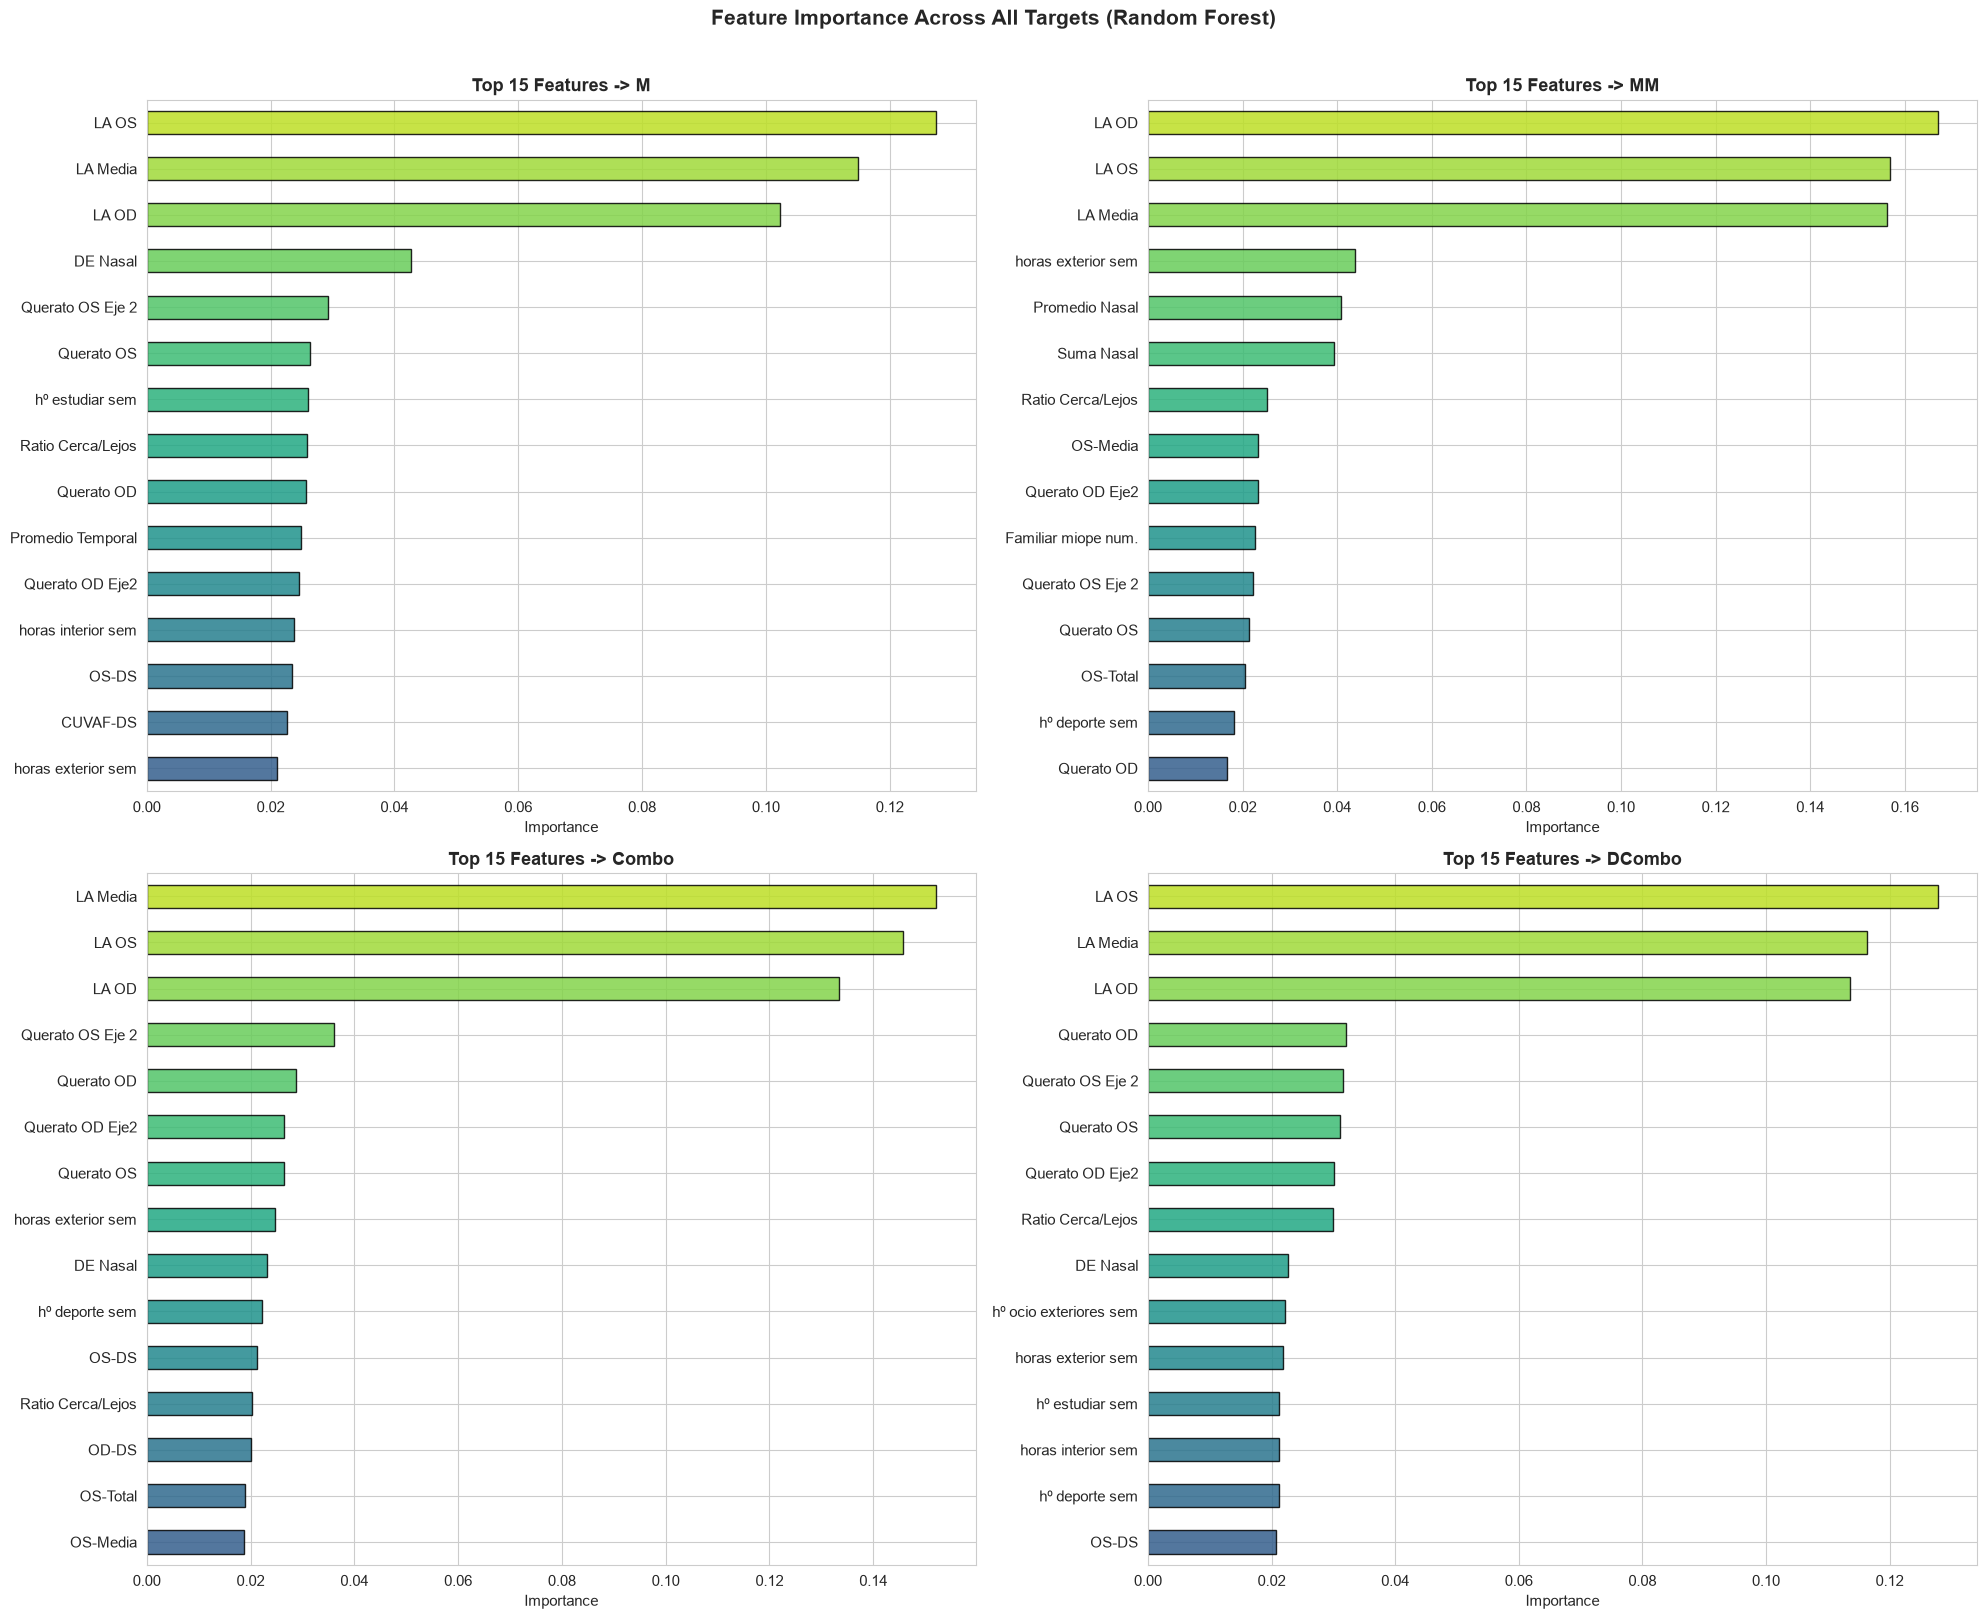

In [25]:
# Feature importance for all 4 targets using Random Forest
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
for idx, target in enumerate(['M', 'MM', 'Combo', 'DCombo']):
    ax = axes[idx // 2][idx % 2]
    rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)
    rf.fit(X_train, Y_train[target])
    imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=True)
    imp.tail(15).plot(kind='barh', ax=ax, color=plt.cm.viridis(np.linspace(0.3, 0.9, 15)),
                      edgecolor='black', alpha=0.85)
    ax.set_title(f'Top 15 Features -> {target}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance')
plt.suptitle('Feature Importance Across All Targets (Random Forest)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Conclusions

1. **Data Preprocessing**: Starting from 49 raw features (mix of numeric and categorical with missing values), we cleaned and reduced to 40 informative numeric features. Dropped date, ancestry, and 100%-missing columns, encoded all categoricals, and imputed missing values.

2. **Key Predictive Features**:
   - **Axial Length (LA)** measurements are the strongest predictors across all targets
   - **Keratometry** and **CUVAF** measurements also contribute significantly
   - Lifestyle factors (hours outdoors/indoors, electronics usage) have lower but non-negligible importance

3. **Model Performance**:
   - Tree-based models (Random Forest, Gradient Boosting) generally outperform SVM for this dataset
   - The **MM target** is the most challenging due to severe class imbalance (only 10/132 positive samples)
   - **DCombo** is the most complex task (4 classes with imbalanced distribution)

4. **Post-Processing**: Logical constraints were enforced to ensure consistency across all 4 predictions:
   - MM=SI implies M=SI, Combo=MM, DCombo=MM
   - M=NO implies MM=NO, Combo=C, DCombo=C

5. **Predictions**: Final test predictions saved to `test_predictions.txt` for submission.

---
*Notebook for the ML Course 2026/27 - University of Navarra*